# Feature engineering decisions

With the test set safely apart, we explore the **training set** to decide which transformations the preprocessing pipeline will apply. Three decisions come out of this notebook: new ratio features, a logarithm for the heavy-tailed columns, and cluster-similarity features for the coordinates.

In [ ]:
import numpy as np
from utils.load_california import load_housing_data

X_train, X_test, y_train, y_test = load_housing_data()

housing_train = X_train.copy()
housing_train["median_house_value"] = y_train  # features and target together, for exploring correlations

## Combining attributes: ratios

The total number of rooms of a district is not very useful if we don't know how many households there are; what we really want is the number of rooms per household. Similarly, the number of bedrooms is more informative compared with the number of rooms, and population per household also seems interesting (see [Feature engineering](../notes/feature_engineering.ipynb)).

In [ ]:
housing_train["rooms_per_house"] = housing_train["total_rooms"] / housing_train["households"]
housing_train["bedrooms_ratio"] = housing_train["total_bedrooms"] / housing_train["total_rooms"]
housing_train["people_per_house"] = housing_train["population"] / housing_train["households"]

In [ ]:
corr_matrix = housing_train.corr(numeric_only=True)
corr_matrix["median_house_value"].sort_values(ascending=False, key=np.abs)

median_house_value    1.000000
median_income         0.687151
bedrooms_ratio       -0.259952
rooms_per_house       0.146255
latitude             -0.142673
total_rooms           0.135140
housing_median_age    0.114146
households            0.064590
total_bedrooms        0.047781
longitude            -0.047466
population           -0.026882
people_per_house     -0.021991
Name: median_house_value, dtype: float64

`bedrooms_ratio` has a much higher correlation with the target than the total number of rooms or bedrooms (houses with a lower bedroom/room ratio tend to be more expensive), and `rooms_per_house` also beats the raw counts.

**Decision:** the pipeline will compute the three ratios `total_bedrooms / total_rooms`, `total_rooms / households` and `population / households`.

## Heavy-tailed columns: logarithm

The count columns and `median_income` are strongly right-skewed, which hurts gradient-based and distance-based models (see [Heavy-tailed distributions](../notes/heavy_tailed_distributions.ipynb)).

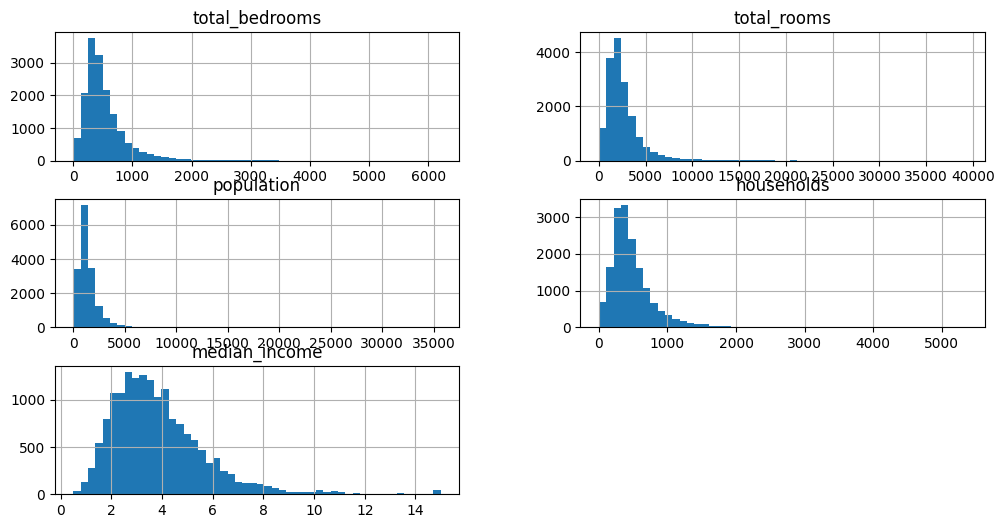

In [ ]:
skewed_columns = ["total_bedrooms", "total_rooms", "population", "households", "median_income"]
X_train[skewed_columns].hist(bins=50, figsize=(12, 6));

A logarithm makes them far more symmetric:

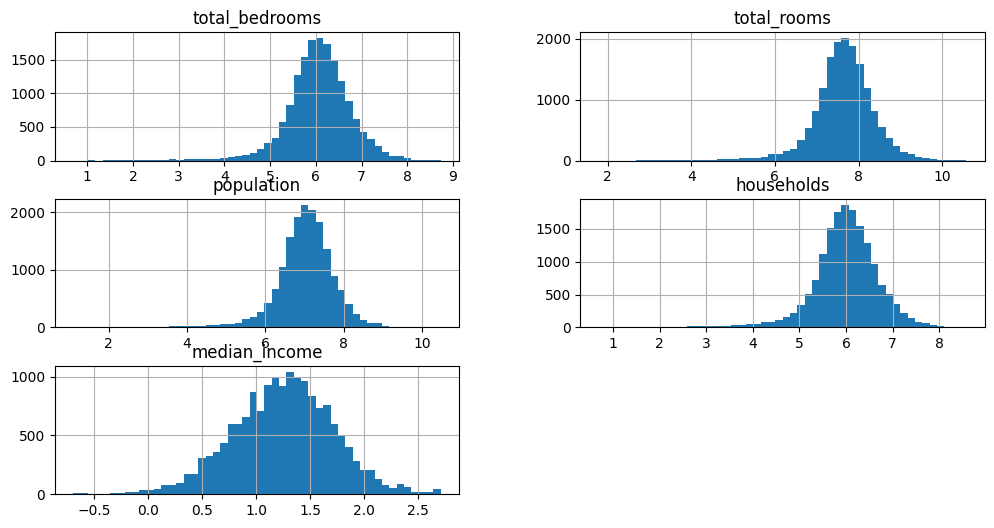

In [ ]:
np.log(X_train[skewed_columns]).hist(bins=50, figsize=(12, 6));

**Decision:** the pipeline will apply `np.log` to these five columns before standardizing them.

## Geographic coordinates: cluster similarity

Latitude and longitude only make sense together, and what matters is proximity to certain places rather than the raw values. The price map of the training set shows it: expensive districts form clusters along the coast and around the big cities.

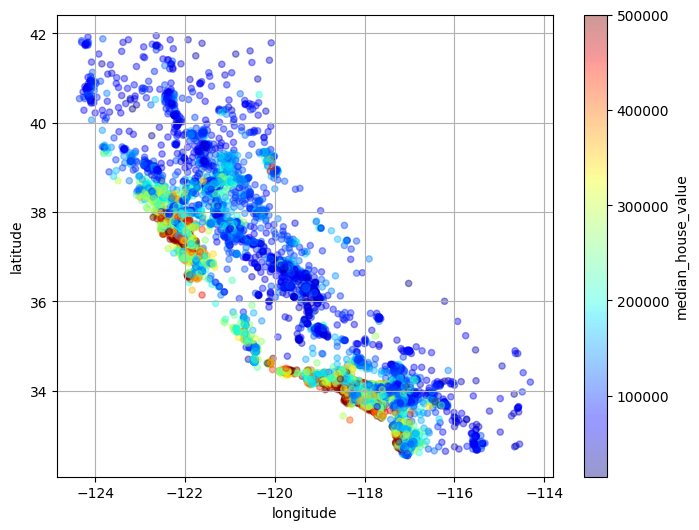

In [ ]:
import matplotlib.pyplot as plt

housing_train.plot(kind="scatter", x="longitude", y="latitude", grid=True, alpha=0.4,
                   c="median_house_value", cmap="jet", colorbar=True, figsize=(8, 6));

**Decision:** the pipeline will replace the two coordinates with the similarity of each district to a set of K-means cluster centers, computed with an RBF kernel. The reasoning, the alternatives (cluster label, distance to the centroid) and the transformer itself are in [Handling geographic coordinates](../notes/geographic_features.ipynb). The number of clusters is a hyperparameter that will be tuned later.

## Summary of decisions

| Input columns | Transformation |
|---|---|
| `total_bedrooms`, `total_rooms` | impute median → ratio (bedrooms / rooms) → standardize |
| `total_rooms`, `households` | impute median → ratio (rooms per house) → standardize |
| `population`, `households` | impute median → ratio (people per house) → standardize |
| `total_bedrooms`, `total_rooms`, `population`, `households`, `median_income` | impute median → log → standardize |
| `latitude`, `longitude` | K-means cluster similarity (RBF kernel) |
| `ocean_proximity` | impute most frequent → one-hot encode |
| `housing_median_age` (remainder) | impute median → standardize |

Imputation is needed because `total_bedrooms` has missing values ([Missing values](../notes/missing_values.ipynb)); standardization because most of the models we will try are sensitive to feature scale ([Feature scaling](../notes/feature_scaling.ipynb)). The pipeline is built in [`05_preprocessing_pipeline.ipynb`](05_preprocessing_pipeline.ipynb).